# 05 - Análisis de Costos y Relación Costo-Desempeño

## Objetivo
- Describir distribución de costos por modelo y sistema
- Evaluar relación costo-desempeño
- Calcular índice de eficiencia (performance / costo normalizado)
- Resumen de tokens consumidos

In [1]:
import polars as pl
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

plt.rcParams.update({"figure.dpi": 120, "figure.figsize": (12, 8)})

DATA_DIR = Path("..") / "part_i" 

In [2]:
df_cost = pl.read_csv(DATA_DIR / "metadata_tokens_cost_cleaned.csv")
print(f"Datos de costos: {df_cost.shape}")
print(f"Columnas: {df_cost.columns}")
print(f"\nPrimeras filas:")
display(df_cost.head(3))

Datos de costos: (711, 27)
Columnas: ['nro_pregunta', 'nro_subpregunta', 'estrategia', 'id_modelo_especialista', 'model_version', 'timestamp', 'provider_name', 'input_tokens', 'output_tokens', 'reasoning_tokens', 'input_price', 'output_price', 'total_price', 'model_input_price_mtok', 'model_output_price_mtok', 'retrieval_id_modelo', 'retrieval_model_version', 'retrieval_timestamp', 'retrieval_provider_name', 'retrieval_input_tokens', 'retrieval_output_tokens', 'retrieval_reasoning_tokens', 'retrieval_input_price', 'retrieval_output_price', 'retrieval_total_price', 'retrieval_model_input_price_mtok', 'retrieval_model_output_price_mtok']

Primeras filas:


nro_pregunta,nro_subpregunta,estrategia,id_modelo_especialista,model_version,timestamp,provider_name,input_tokens,output_tokens,reasoning_tokens,input_price,output_price,total_price,model_input_price_mtok,model_output_price_mtok,retrieval_id_modelo,retrieval_model_version,retrieval_timestamp,retrieval_provider_name,retrieval_input_tokens,retrieval_output_tokens,retrieval_reasoning_tokens,retrieval_input_price,retrieval_output_price,retrieval_total_price,retrieval_model_input_price_mtok,retrieval_model_output_price_mtok
i64,i64,str,str,str,str,str,i64,i64,i64,f64,f64,f64,f64,f64,str,str,str,str,i64,i64,i64,f64,f64,f64,f64,f64
1,1,"""llm_responses_no_rag""","""gpt-5-nano""","""gpt-5-nano-2025-08-07""","""2025-10-19T14:30:05+00:00""","""openai""",315,7818,7296,0.000016,0.0031272,0.003143,0.05,0.4,null,null,null,null,null,null,null,null,null,null,null,null
1,1,"""llm_responses_no_rag""","""gpt-5-mini""","""gpt-5-mini-2025-08-07""","""2025-10-19T14:31:00+00:00""","""openai""",315,2539,1600,0.000079,0.005078,0.005157,0.25,2.0,null,null,null,null,null,null,null,null,null,null,null,null
1,1,"""llm_responses_no_rag""","""gpt-5""","""gpt-5-2025-08-07""","""2025-10-19T14:31:29+00:00""","""openai""",315,4639,3968,0.000394,0.04639,0.046784,1.25,10.0,null,null,null,null,null,null,null,null,null,null,null,null


In [3]:
# Calcular costo total (respuesta + retrieval si existe)
df_cost = df_cost.with_columns(
    (
        pl.col("total_price") +
        pl.col("retrieval_total_price").fill_null(0)
    ).alias("costo_total")
)

# Verificar columnas de estrategia y modelo
print(f"Estrategias: {df_cost['estrategia'].unique().to_list()}")
print(f"Modelos: {df_cost['id_modelo_especialista'].unique().to_list()}")

ESTRATEGIAS = sorted(df_cost["estrategia"].unique().to_list())
MODELOS = sorted(df_cost["id_modelo_especialista"].unique().to_list())

Estrategias: ['llm_responses_base_rag', 'llm_responses_agentic_rag', 'llm_responses_no_rag']
Modelos: ['gpt-5-nano', 'gpt-5', 'gpt-5-mini']


## 1. Costos descriptivos por modelo y sistema

In [4]:
# Resumen por modelo
print("=== Costo total por MODELO ===")
resumen_modelo = df_cost.group_by("id_modelo_especialista").agg(
    pl.col("costo_total").mean().alias("media"),
    pl.col("costo_total").median().alias("mediana"),
    pl.col("costo_total").std().alias("std"),
    pl.col("costo_total").sum().alias("suma_total"),
    pl.col("costo_total").count().alias("n"),
).sort("id_modelo_especialista")
display(resumen_modelo)

print("\n=== Costo total por SISTEMA ===")
resumen_sistema = df_cost.group_by("estrategia").agg(
    pl.col("costo_total").mean().alias("media"),
    pl.col("costo_total").median().alias("mediana"),
    pl.col("costo_total").std().alias("std"),
    pl.col("costo_total").sum().alias("suma_total"),
    pl.col("costo_total").count().alias("n"),
).sort("estrategia")
display(resumen_sistema)

=== Costo total por MODELO ===


id_modelo_especialista,media,mediana,std,suma_total,n
str,f64,f64,f64,f64,u32
"""gpt-5""",0.055383,0.050284,0.025748,13.125732,237
"""gpt-5-mini""",0.022106,0.0059825,0.025282,5.2390117,237
"""gpt-5-nano""",0.016579,0.003123,0.021522,3.929127,237



=== Costo total por SISTEMA ===


estrategia,media,mediana,std,suma_total,n
str,f64,f64,f64,f64,u32
"""llm_responses_agentic_rag""",0.060067,0.055039,0.02388,14.235888,237
"""llm_responses_base_rag""",0.015811,0.0053485,0.018736,3.747315,237
"""llm_responses_no_rag""",0.018188,0.004075,0.022009,4.310667,237


In [5]:
# Resumen por modelo × sistema
print("=== Costo total por MODELO × SISTEMA ===")
resumen_cruzado = df_cost.group_by(["estrategia", "id_modelo_especialista"]).agg(
    pl.col("costo_total").mean().alias("media"),
    pl.col("costo_total").median().alias("mediana"),
    pl.col("costo_total").sum().alias("suma_total"),
    pl.col("costo_total").count().alias("n"),
).sort("estrategia", "id_modelo_especialista")
display(resumen_cruzado)

=== Costo total por MODELO × SISTEMA ===


estrategia,id_modelo_especialista,media,mediana,suma_total,n
str,str,f64,f64,f64,u32
"""llm_responses_agentic_rag""","""gpt-5""",0.079152,0.073496,6.2529875,79
"""llm_responses_agentic_rag""","""gpt-5-mini""",0.056367,0.0558335,4.4529917,79
"""llm_responses_agentic_rag""","""gpt-5-nano""",0.044682,0.043162,3.529909,79
"""llm_responses_base_rag""","""gpt-5""",0.039237,0.038325,3.09969,79
"""llm_responses_base_rag""","""gpt-5-mini""",0.005652,0.005333,0.446495,79
"""llm_responses_base_rag""","""gpt-5-nano""",0.002546,0.0024313,0.201129,79
"""llm_responses_no_rag""","""gpt-5""",0.04776,0.0481075,3.773054,79
"""llm_responses_no_rag""","""gpt-5-mini""",0.004298,0.004075,0.339525,79
"""llm_responses_no_rag""","""gpt-5-nano""",0.002507,0.0024472,0.198089,79


## 2. Visualización de costos

/tmp/ipykernel_92095/263953473.py:44: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax2.boxplot(data_for_bp, labels=labels_bp, patch_artist=True)


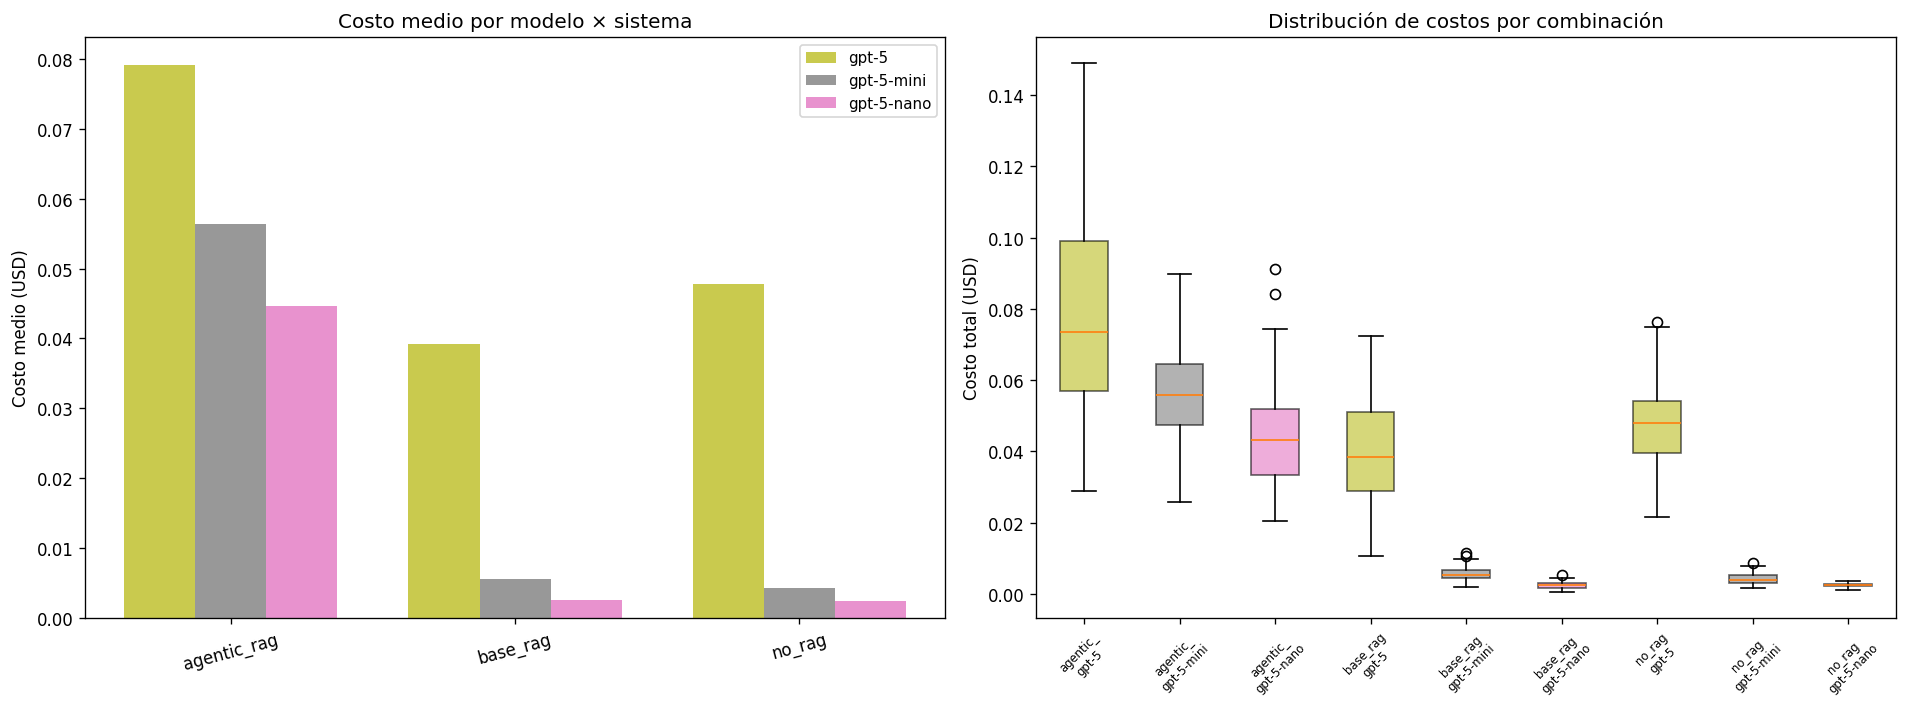

In [6]:
colores_modelo = {"gpt-5-nano": "#e377c2", "gpt-5-mini": "#7f7f7f", "gpt-5": "#bcbd22"}
est_labels = [e.replace("llm_responses_", "") for e in ESTRATEGIAS]

# Barras agrupadas: costo medio por modelo×sistema
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# --- Panel izquierdo: barras agrupadas ---
ax = axes[0]
x = np.arange(len(ESTRATEGIAS))
width = 0.25

for i, modelo in enumerate(MODELOS):
    means = []
    for est in ESTRATEGIAS:
        val = df_cost.filter(
            (pl.col("estrategia") == est) &
            (pl.col("id_modelo_especialista") == modelo)
        )["costo_total"].mean()
        means.append(val if val is not None else 0)

    ax.bar(x + i * width, means, width, label=modelo,
           color=colores_modelo[modelo], alpha=0.8)

ax.set_xticks(x + width)
ax.set_xticklabels(est_labels, rotation=15)
ax.set_ylabel("Costo medio (USD)")
ax.set_title("Costo medio por modelo × sistema")
ax.legend(fontsize=9)

# --- Panel derecho: boxplots ---
ax2 = axes[1]
data_for_bp = []
labels_bp = []

for est in ESTRATEGIAS:
    for modelo in MODELOS:
        vals = df_cost.filter(
            (pl.col("estrategia") == est) &
            (pl.col("id_modelo_especialista") == modelo)
        )["costo_total"].drop_nulls().to_numpy()
        data_for_bp.append(vals)
        labels_bp.append(f"{est.replace('llm_responses_', '')[:8]}\n{modelo}")

bp = ax2.boxplot(data_for_bp, labels=labels_bp, patch_artist=True)
n_combos = len(MODELOS)
for j, patch in enumerate(bp["boxes"]):
    modelo_idx = j % n_combos
    modelo_name = MODELOS[modelo_idx]
    patch.set_facecolor(colores_modelo[modelo_name])
    patch.set_alpha(0.6)

ax2.set_ylabel("Costo total (USD)")
ax2.set_title("Distribución de costos por combinación")
ax2.tick_params(axis="x", rotation=45, labelsize=7)

plt.tight_layout()
plt.show()

## 3. Relación costo-desempeño

Para cada combinación modelo×sistema, graficar el costo medio vs. desempeño medio en cada métrica.

In [7]:
# Cargar métricas de desempeño
df_perf = pl.read_csv(DATA_DIR / "combined_metrics_for_analysis.csv")

VR_SELECCIONADAS = [
    "token_f1", "rouge_l", "sbert_similarity_spanish",
    "bertscore", "respuesta_correcta_avg", "precision_legal_avg",
]

# Calcular medias de costo y desempeño por combinación
scatter_data = []

for est in ESTRATEGIAS:
    for modelo in MODELOS:
        # Costo medio
        costo_medio = df_cost.filter(
            (pl.col("estrategia") == est) &
            (pl.col("id_modelo_especialista") == modelo)
        )["costo_total"].mean()

        # Desempeño medio por métrica
        perf_row = {"estrategia": est, "modelo": modelo, "costo_medio": costo_medio}
        for metrica in VR_SELECCIONADAS:
            val = df_perf.filter(
                (pl.col("estrategia") == est) &
                (pl.col("id_modelo_especialista") == modelo)
            )[metrica].mean()
            perf_row[metrica] = val

        scatter_data.append(perf_row)

df_scatter = pl.DataFrame(scatter_data)
display(df_scatter)

estrategia,modelo,costo_medio,token_f1,rouge_l,sbert_similarity_spanish,bertscore,respuesta_correcta_avg,precision_legal_avg
str,str,f64,f64,f64,f64,f64,f64,f64
"""llm_responses_agentic_rag""","""gpt-5""",0.079152,0.296615,0.208077,0.785877,0.71491,0.803509,0.768202
"""llm_responses_agentic_rag""","""gpt-5-mini""",0.056367,0.223938,0.142846,0.766935,0.710394,0.778728,0.691009
"""llm_responses_agentic_rag""","""gpt-5-nano""",0.044682,0.154025,0.111716,0.448313,0.449908,0.396491,0.339474
"""llm_responses_base_rag""","""gpt-5""",0.039237,0.286259,0.198304,0.784999,0.716232,0.694079,0.60614
"""llm_responses_base_rag""","""gpt-5-mini""",0.005652,0.233571,0.155209,0.752089,0.706172,0.633772,0.518202
"""llm_responses_base_rag""","""gpt-5-nano""",0.002546,0.267289,0.178586,0.762458,0.714129,0.58443,0.437719
"""llm_responses_no_rag""","""gpt-5""",0.04776,0.239996,0.146696,0.756828,0.695305,0.730482,0.376754
"""llm_responses_no_rag""","""gpt-5-mini""",0.004298,0.182552,0.123696,0.605595,0.673878,0.344298,0.007675
"""llm_responses_no_rag""","""gpt-5-nano""",0.002507,0.204065,0.126385,0.710194,0.686629,0.57818,0.01864


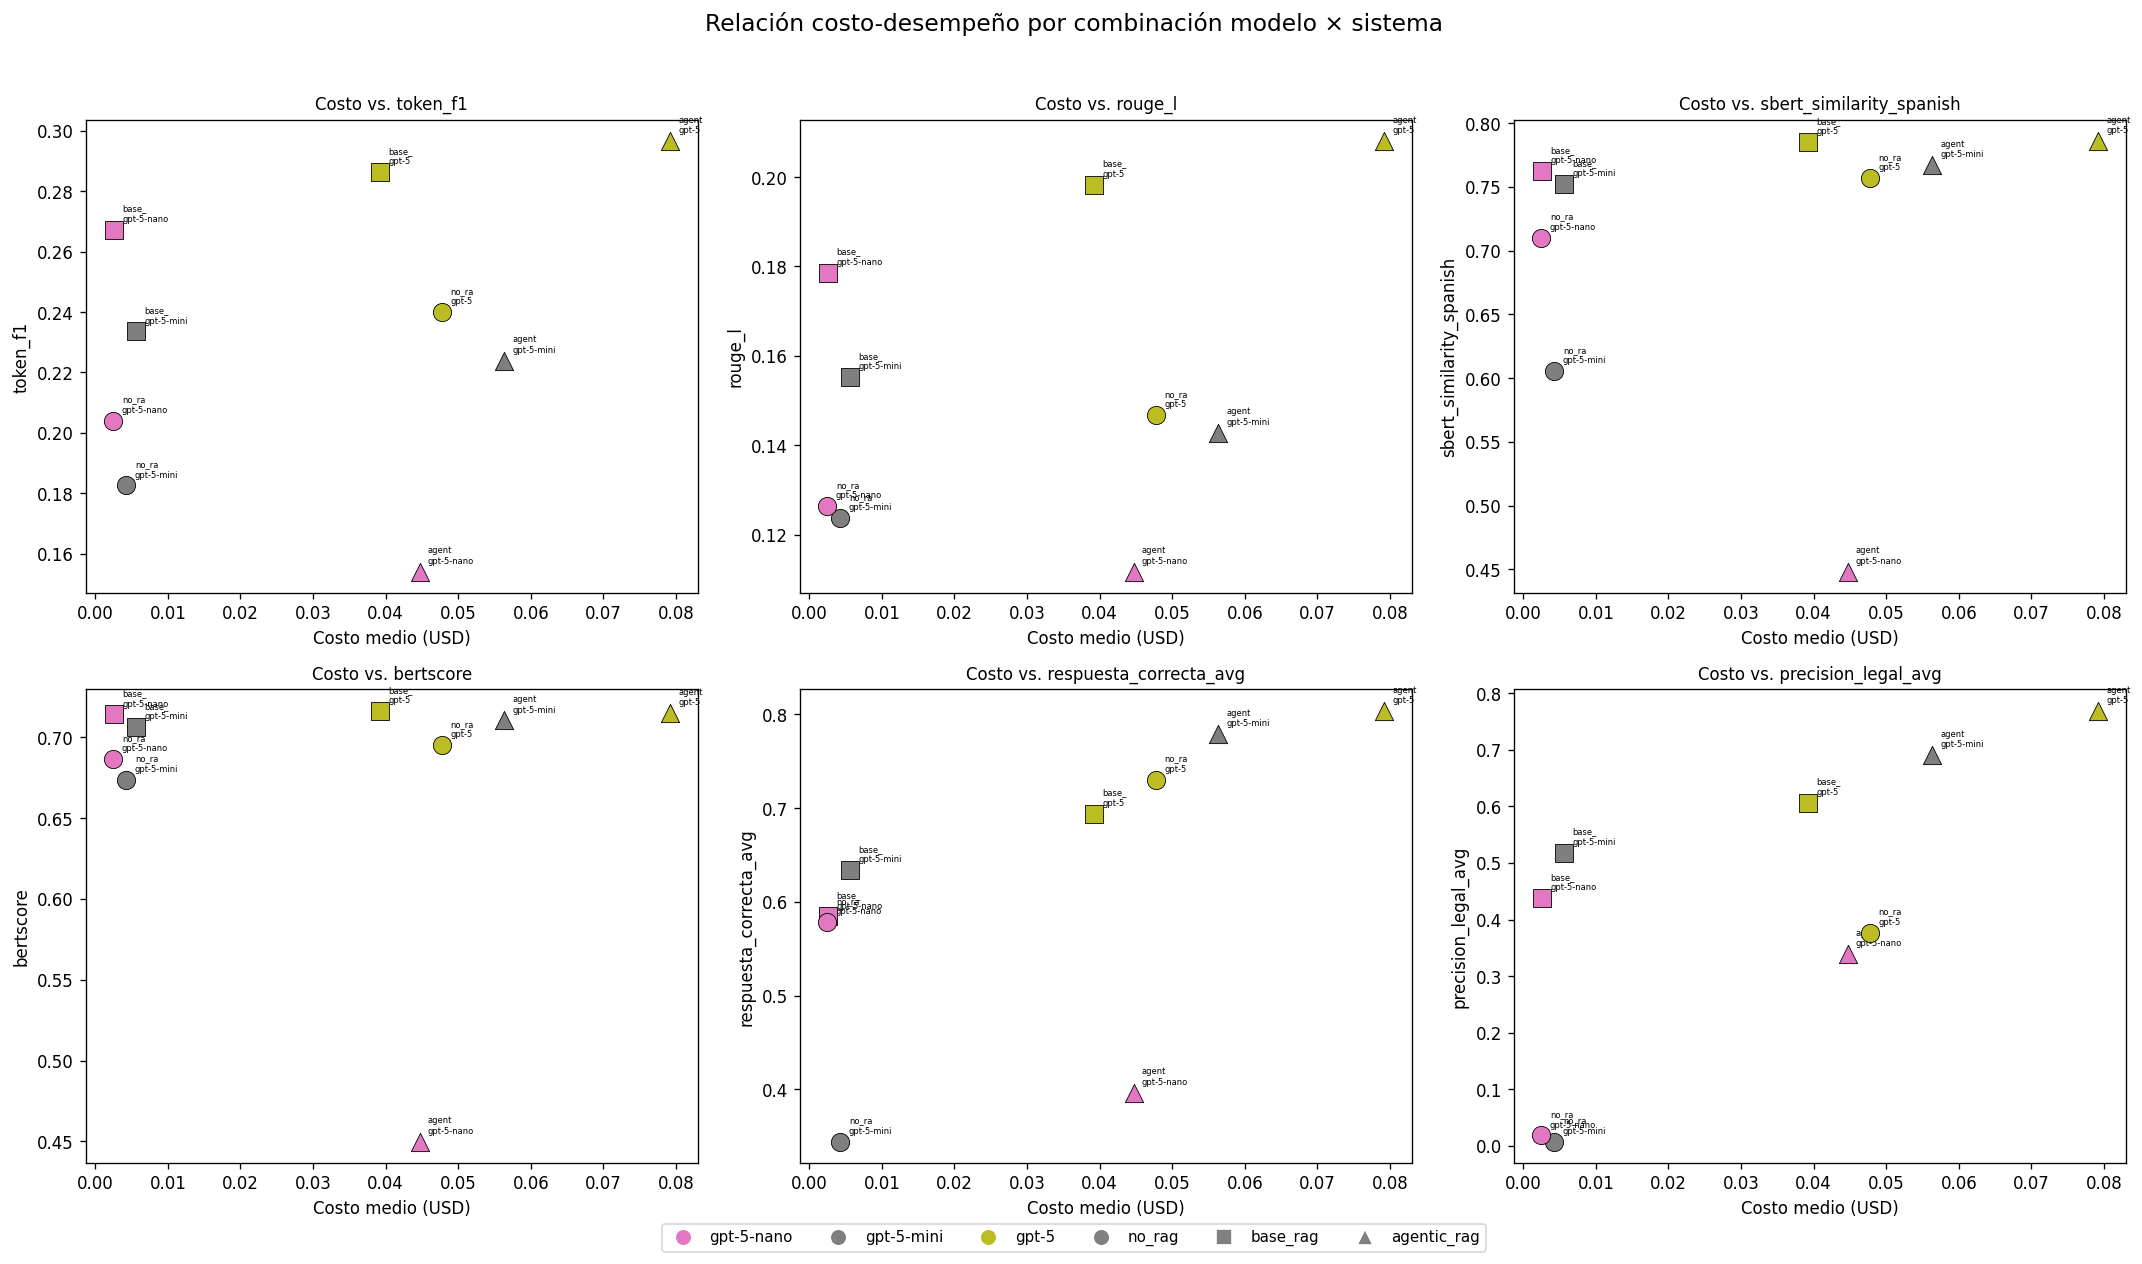

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

markers_est = {
    "llm_responses_no_rag": "o",
    "llm_responses_base_rag": "s",
    "llm_responses_agentic_rag": "^",
}

for i, metrica in enumerate(VR_SELECCIONADAS):
    ax = axes[i]

    for _, row in enumerate(df_scatter.iter_rows(named=True)):
        est = row["estrategia"]
        modelo = row["modelo"]
        costo = row["costo_medio"]
        perf = row[metrica]

        if costo is not None and perf is not None:
            ax.scatter(
                costo, perf,
                color=colores_modelo[modelo],
                marker=markers_est[est],
                s=120, edgecolors="black", linewidth=0.5,
                zorder=5,
            )
            label = f"{est.replace('llm_responses_', '')[:5]}\n{modelo}"
            ax.annotate(label, (costo, perf), fontsize=5,
                       textcoords="offset points", xytext=(5, 5))

    ax.set_xlabel("Costo medio (USD)")
    ax.set_ylabel(metrica)
    ax.set_title(f"Costo vs. {metrica}", fontsize=10)

# Leyenda manual
from matplotlib.lines import Line2D
legend_elements = []
for modelo, color in colores_modelo.items():
    legend_elements.append(Line2D([0], [0], marker="o", color="w",
                                  markerfacecolor=color, markersize=10, label=modelo))
for est, marker in markers_est.items():
    legend_elements.append(Line2D([0], [0], marker=marker, color="w",
                                  markerfacecolor="gray", markersize=10,
                                  label=est.replace("llm_responses_", "")))

fig.legend(handles=legend_elements, loc="lower center", ncol=6, fontsize=9,
           bbox_to_anchor=(0.5, -0.02))
fig.suptitle("Relación costo-desempeño por combinación modelo × sistema", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

## 4. Índice de eficiencia

Eficiencia = desempeño / costo normalizado (min-max normalización del costo)

In [9]:
# Normalizar costo (min-max)
costos = [r["costo_medio"] for r in scatter_data if r["costo_medio"] is not None]
costo_min = min(costos)
costo_max = max(costos)
costo_range = costo_max - costo_min if costo_max != costo_min else 1

efficiency_data = []
for row in scatter_data:
    if row["costo_medio"] is not None:
        costo_norm = (row["costo_medio"] - costo_min) / costo_range
        # Evitar división por 0 para el costo más bajo
        costo_norm = max(costo_norm, 0.01)

        eff_row = {
            "estrategia": row["estrategia"].replace("llm_responses_", ""),
            "modelo": row["modelo"],
            "costo_medio": row["costo_medio"],
            "costo_normalizado": round(costo_norm, 4),
        }
        for metrica in VR_SELECCIONADAS:
            val = row.get(metrica)
            if val is not None:
                eff_row[f"eficiencia_{metrica}"] = round(val / costo_norm, 4)
        efficiency_data.append(eff_row)

df_eff = pl.DataFrame(efficiency_data)
display(df_eff)

estrategia,modelo,costo_medio,costo_normalizado,eficiencia_token_f1,eficiencia_rouge_l,eficiencia_sbert_similarity_spanish,eficiencia_bertscore,eficiencia_respuesta_correcta_avg,eficiencia_precision_legal_avg
str,str,f64,f64,f64,f64,f64,f64,f64,f64
"""agentic_rag""","""gpt-5""",0.079152,1.0,0.2966,0.2081,0.7859,0.7149,0.8035,0.7682
"""agentic_rag""","""gpt-5-mini""",0.056367,0.7027,0.3187,0.2033,1.0914,1.0109,1.1082,0.9833
"""agentic_rag""","""gpt-5-nano""",0.044682,0.5503,0.2799,0.203,0.8147,0.8176,0.7205,0.6169
"""base_rag""","""gpt-5""",0.039237,0.4792,0.5974,0.4138,1.6381,1.4946,1.4484,1.2649
"""base_rag""","""gpt-5-mini""",0.005652,0.041,5.6933,3.7832,18.3321,17.2129,15.4482,12.6312
"""base_rag""","""gpt-5-nano""",0.002546,0.01,26.7289,17.8586,76.2458,71.4129,58.443,43.7719
"""no_rag""","""gpt-5""",0.04776,0.5904,0.4065,0.2485,1.2818,1.1776,1.2372,0.6381
"""no_rag""","""gpt-5-mini""",0.004298,0.0234,7.8151,5.2955,25.9257,28.8489,14.7395,0.3286
"""no_rag""","""gpt-5-nano""",0.002507,0.01,20.4065,12.6385,71.0194,68.6629,57.818,1.864


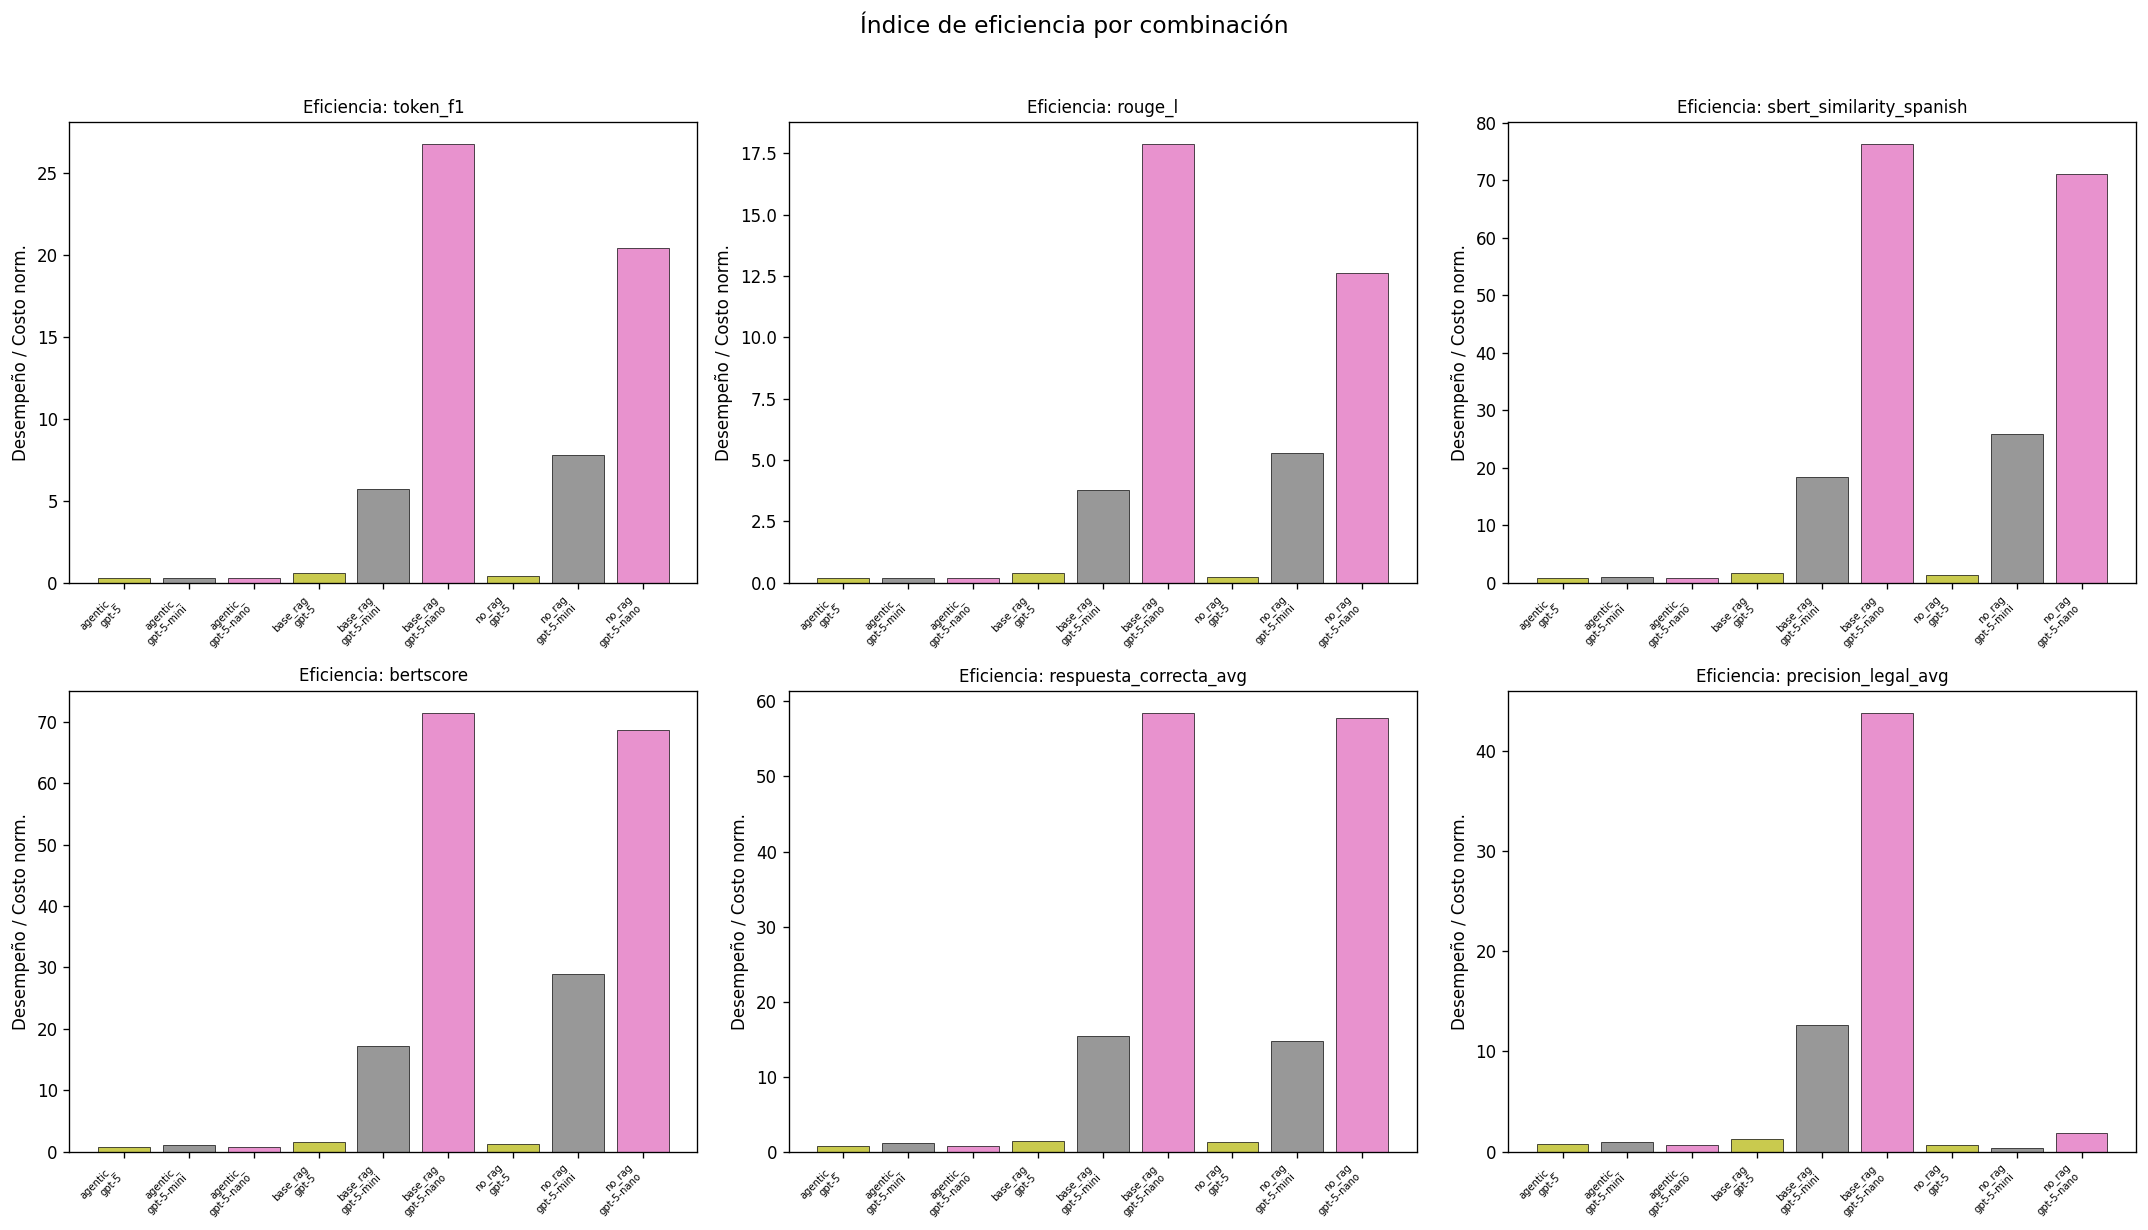

In [10]:
# Gráfico de barras de eficiencia
eff_cols = [f"eficiencia_{m}" for m in VR_SELECCIONADAS]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

labels = [f"{r['estrategia'][:8]}\n{r['modelo']}" for r in efficiency_data]

for i, metrica in enumerate(VR_SELECCIONADAS):
    ax = axes[i]
    col = f"eficiencia_{metrica}"
    vals = df_eff[col].to_numpy()

    colors = [colores_modelo[r["modelo"]] for r in efficiency_data]

    bars = ax.bar(range(len(vals)), vals, color=colors, alpha=0.8, edgecolor="black", linewidth=0.5)
    ax.set_xticks(range(len(labels)))
    ax.set_xticklabels(labels, rotation=45, fontsize=6, ha="right")
    ax.set_title(f"Eficiencia: {metrica}", fontsize=10)
    ax.set_ylabel("Desempeño / Costo norm.")

fig.suptitle("Índice de eficiencia por combinación", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

## 5. Resumen de tokens

In [11]:
# Columnas de tokens
token_cols = [c for c in df_cost.columns if "token" in c.lower() and c != "token_f1"]
print(f"Columnas de tokens: {token_cols}")

if token_cols:
    # Resumen de tokens por modelo
    print("\n=== Tokens por modelo ===")
    for col in token_cols:
        resumen = df_cost.group_by("id_modelo_especialista").agg(
            pl.col(col).sum().alias("total"),
            pl.col(col).mean().alias("media"),
        ).sort("id_modelo_especialista")
        print(f"\n{col}:")
        display(resumen)

print("\n=== Costo total del experimento ===")
costo_total_experimento = df_cost["costo_total"].sum()
print(f"Costo total: USD {costo_total_experimento:.4f}")

for est in ESTRATEGIAS:
    costo_est = df_cost.filter(pl.col("estrategia") == est)["costo_total"].sum()
    print(f"  {est.replace('llm_responses_', '')}: USD {costo_est:.4f}")

Columnas de tokens: ['input_tokens', 'output_tokens', 'reasoning_tokens', 'retrieval_input_tokens', 'retrieval_output_tokens', 'retrieval_reasoning_tokens']

=== Tokens por modelo ===

input_tokens:


id_modelo_especialista,total,media
str,i64,f64
"""gpt-5""",555359,2343.28692
"""gpt-5-mini""",528940,2231.814346
"""gpt-5-nano""",494154,2085.037975



output_tokens:


id_modelo_especialista,total,media
str,i64,f64
"""gpt-5""",948158,4000.666667
"""gpt-5-mini""",547913,2311.869198
"""gpt-5-nano""",1283019,5413.582278



reasoning_tokens:


id_modelo_especialista,total,media
str,i64,f64
"""gpt-5""",807680,3407.932489
"""gpt-5-mini""",363136,1532.219409
"""gpt-5-nano""",1140416,4811.881857


... (3 outputs left out)

id_modelo_especialista,total,media
str,i64,f64
"""gpt-5""",519537,6576.417722
"""gpt-5-mini""",547699,6932.898734
"""gpt-5-nano""",492410,6233.037975



retrieval_reasoning_tokens:


id_modelo_especialista,total,media
str,i64,f64
"""gpt-5""",348480,4411.139241
"""gpt-5-mini""",397952,5037.367089
"""gpt-5-nano""",379776,4807.291139



=== Costo total del experimento ===
Costo total: USD 22.2939
  agentic_rag: USD 14.2359
  base_rag: USD 3.7473
  no_rag: USD 4.3107
